<a href="https://colab.research.google.com/github/Pavithra1912006/Employee_Attrition_Analysis/blob/main/Employee_Attrition_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd

employees = pd.read_csv("/content/employees.csv")
attendance = pd.read_csv("/content/attendance.csv")
compensation = pd.read_csv("/content/compensation.csv")
engagement = pd.read_csv("/content/engagement.csv")
movement = pd.read_csv("/content/movement.csv")

print("Employees:", employees.shape)
print("Attendance:", attendance.shape)
print("Compensation:", compensation.shape)
print("Engagement:", engagement.shape)
print("Movement:", movement.shape)


Employees: (501, 5)
Attendance: (500, 4)
Compensation: (500, 5)
Engagement: (500, 3)
Movement: (500, 4)


In [2]:

print("EMPLOYEES DATA")
display(employees.head())

print("ATTENDANCE DATA")
display(attendance.head())

print("COMPENSATION DATA")
display(compensation.head())

print("ENGAGEMENT DATA")
display(engagement.head())

print("MOVEMENT DATA")
display(movement.head())


EMPLOYEES DATA


,employee_id,department,role,tenure_years,grade
0,E0001,Operations,Operations Manager,3.5,G1
1,E0002,HR,HR Manager,0.3,G4
2,E0003,Customer Support,Support Specialist,1.7,G2
3,E0004,Operations,Operations Manager,4.6,G1
4,E0005,Engineering,Software Engineer,1.4,G2


ATTENDANCE DATA


,employee_id,absence_days,overtime_hours_monthly,leave_days_yearly
0,E0001,0.8,7.1,11.6
1,E0002,4.3,19.9,10.8
2,E0003,7.6,16.3,14.6
3,E0004,7.9,11.9,12.0
4,E0005,0.6,9.5,8.5


COMPENSATION DATA


,employee_id,salary_band,annual_salary_inr,increment_percent,benefits_level
0,E0001,B3,721890,1.9,Standard
1,E0002,B3,666038,8.6,Enhanced
2,E0003,B1,324036,10.3,Standard
3,E0004,B1,285544,7.2,Standard
4,E0005,B5,1241449,13.4,Enhanced


ENGAGEMENT DATA


,employee_id,survey_score,participation_percent
0,E0001,3.3,71
1,E0002,2.6,100
2,E0003,3.8,94
3,E0004,NaN,58
4,E0005,NaN,70


MOVEMENT DATA


,employee_id,promotions_count,transfers_count,exit_status
0,E0001,0.0,0,Stayed
1,E0002,0.0,0,Left
2,E0003,0.0,0,Left
3,E0004,1.0,0,Stayed
4,E0005,0.0,0,Left


In [3]:

datasets = {
    "employees": employees,
    "attendance": attendance,
    "compensation": compensation,
    "engagement": engagement,
    "movement": movement
}

for name, df in datasets.items():
    print("\nDataset:", name)
    print("Missing values:")
    print(df.isnull().sum())
    print("Duplicate rows:", df.duplicated().sum())
    print("Columns:", df.columns.tolist())



Dataset: employees
Missing values:
employee_id     0
department      0
role            0
tenure_years    0
grade           0
dtype: int64
Duplicate rows: 1
Columns: ['employee_id', 'department', 'role', 'tenure_years', 'grade']

Dataset: attendance
Missing values:
employee_id               0
absence_days              0
overtime_hours_monthly    0
leave_days_yearly         0
dtype: int64
Duplicate rows: 0
Columns: ['employee_id', 'absence_days', 'overtime_hours_monthly', 'leave_days_yearly']

Dataset: compensation
Missing values:
employee_id          0
salary_band          0
annual_salary_inr    0
increment_percent    0
benefits_level       0
dtype: int64
Duplicate rows: 0
Columns: ['employee_id', 'salary_band', 'annual_salary_inr', 'increment_percent', 'benefits_level']

Dataset: engagement
Missing values:
employee_id               0
survey_score             28
participation_percent     0
dtype: int64
Duplicate rows: 0
Columns: ['employee_id', 'survey_score', 'participation_percent']


In [4]:

print("Total employee rows:", len(employees))
print("Unique employee IDs:", employees["employee_id"].nunique())

duplicates = employees[
    employees.duplicated(subset="employee_id", keep=False)
]

display(duplicates)


Total employee rows: 501
Unique employee IDs: 500


,employee_id,department,role,tenure_years,grade
17,E0018,Engineering,Data Analyst,11.0,G2
500,E0018,Engineering,Data Analyst,11.0,G2


In [5]:

employees["role"] = (
    employees["role"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
)

print(employees["role"].value_counts())


role
operations manager      44
operations associate    44
qa engineer             41
team lead               36
data analyst            36
account manager         31
engineering manager     30
finance manager         28
sales executive         26
software engineer       26
support manager         24
sales manager           21
support specialist      21
support associate       21
hr executive            17
financial analyst       17
hr manager              16
recruiter               12
accountant              10
Name: count, dtype: Int64


In [6]:

print("Missing engagement scores:")
print(engagement["survey_score"].isnull().sum())

print("\nMissing promotion history:")
print(movement["promotions_count"].isnull().sum())


Missing engagement scores:
28

Missing promotion history:
22


In [8]:

# Find columns containing the word "overtime"
overtime_columns = [
    col for col in attendance.columns
    if "overtime" in col.lower()
]

print("Overtime columns found:", overtime_columns)

if overtime_columns:
    col = overtime_columns[0]
    print(attendance[col].describe())
    display(attendance[attendance[col] > 60])
else:
    print("No overtime column found. Check the column names above.")


Overtime columns found: ['overtime_hours_monthly']
count    500.000000
mean      12.885800
std       12.526382
min        0.000000
25%        6.400000
50%       11.900000
75%       17.025000
max      160.000000
Name: overtime_hours_monthly, dtype: float64


,employee_id,absence_days,overtime_hours_monthly,leave_days_yearly
85,E0086,2.6,110.0,14.0
197,E0198,2.1,160.0,13.7
310,E0311,2.0,95.0,17.0
414,E0415,1.3,125.0,12.4


In [10]:

for name, df in {
    "employees": employees,
    "attendance": attendance,
    "compensation": compensation,
    "engagement": engagement,
    "movement": movement
}.items():
    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Duplicate employee IDs:",
          df["employee_id"].duplicated().sum())



employees
Shape: (501, 5)
Duplicate employee IDs: 1

attendance
Shape: (500, 4)
Duplicate employee IDs: 0

compensation
Shape: (500, 5)
Duplicate employee IDs: 0

engagement
Shape: (500, 3)
Duplicate employee IDs: 0

movement
Shape: (500, 4)
Duplicate employee IDs: 0


In [11]:

for name, df in {
    "employees": employees,
    "attendance": attendance,
    "compensation": compensation,
    "engagement": engagement,
    "movement": movement
}.items():
    print(f"\n{name.upper()}")
    print(df.columns.tolist())



EMPLOYEES
['employee_id', 'department', 'role', 'tenure_years', 'grade']

ATTENDANCE
['employee_id', 'absence_days', 'overtime_hours_monthly', 'leave_days_yearly']

COMPENSATION
['employee_id', 'salary_band', 'annual_salary_inr', 'increment_percent', 'benefits_level']

ENGAGEMENT
['employee_id', 'survey_score', 'participation_percent']

MOVEMENT
['employee_id', 'promotions_count', 'transfers_count', 'exit_status']


In [12]:

print(
    employees[
        employees.duplicated("employee_id", keep=False)
    ].sort_values("employee_id")
)


    employee_id   department          role  tenure_years grade
17        E0018  Engineering  data analyst          11.0    G2
500       E0018  Engineering  data analyst          11.0    G2


In [13]:

datasets = {
    "employees": employees,
    "attendance": attendance,
    "compensation": compensation,
    "engagement": engagement,
    "movement": movement
}

for name, df in datasets.items():
    print(
        name,
        "| Rows:", len(df),
        "| Unique IDs:", df["employee_id"].nunique(),
        "| Duplicate IDs:", df["employee_id"].duplicated().sum()
    )


employees | Rows: 501 | Unique IDs: 500 | Duplicate IDs: 1
attendance | Rows: 500 | Unique IDs: 500 | Duplicate IDs: 0
compensation | Rows: 500 | Unique IDs: 500 | Duplicate IDs: 0
engagement | Rows: 500 | Unique IDs: 500 | Duplicate IDs: 0
movement | Rows: 500 | Unique IDs: 500 | Duplicate IDs: 0


In [15]:

print("Duplicate employee records:")

display(
    employees[
        employees.duplicated(
            subset="employee_id",
            keep=False
        )
    ].sort_values("employee_id")
)


Duplicate employee records:


,employee_id,department,role,tenure_years,grade
17,E0018,Engineering,data analyst,11.0,G2
500,E0018,Engineering,data analyst,11.0,G2


In [16]:

employees = employees.drop_duplicates(
    subset="employee_id",
    keep="first"
).copy()

print("Rows after duplicate removal:", len(employees))
print("Unique employee IDs:", employees["employee_id"].nunique())


Rows after duplicate removal: 500
Unique employee IDs: 500


In [17]:

datasets = {
    "employees": employees,
    "attendance": attendance,
    "compensation": compensation,
    "engagement": engagement,
    "movement": movement
}

for name, df in datasets.items():
    print(
        name,
        "| Rows:", len(df),
        "| Unique IDs:", df["employee_id"].nunique(),
        "| Duplicate IDs:", df["employee_id"].duplicated().sum()
    )


employees | Rows: 500 | Unique IDs: 500 | Duplicate IDs: 0
attendance | Rows: 500 | Unique IDs: 500 | Duplicate IDs: 0
compensation | Rows: 500 | Unique IDs: 500 | Duplicate IDs: 0
engagement | Rows: 500 | Unique IDs: 500 | Duplicate IDs: 0
movement | Rows: 500 | Unique IDs: 500 | Duplicate IDs: 0


In [18]:

master = employees.copy()

for name, df in [
    ("attendance", attendance),
    ("compensation", compensation),
    ("engagement", engagement),
    ("movement", movement)
]:
    master = master.merge(
        df,
        on="employee_id",
        how="left",
        validate="one_to_one",
        suffixes=("", f"_{name}")
    )

print("Master dataset shape:", master.shape)
display(master.head())


Master dataset shape: (500, 17)


,employee_id,department,role,tenure_years,grade,absence_days,overtime_hours_monthly,leave_days_yearly,salary_band,annual_salary_inr,increment_percent,benefits_level,survey_score,participation_percent,promotions_count,transfers_count,exit_status
0,E0001,Operations,operations manager,3.5,G1,0.8,7.1,11.6,B3,721890,1.9,Standard,3.3,71,0.0,0,Stayed
1,E0002,HR,hr manager,0.3,G4,4.3,19.9,10.8,B3,666038,8.6,Enhanced,2.6,100,0.0,0,Left
2,E0003,Customer Support,support specialist,1.7,G2,7.6,16.3,14.6,B1,324036,10.3,Standard,3.8,94,0.0,0,Left
3,E0004,Operations,operations manager,4.6,G1,7.9,11.9,12.0,B1,285544,7.2,Standard,NaN,58,1.0,0,Stayed
4,E0005,Engineering,software engineer,1.4,G2,0.6,9.5,8.5,B5,1241449,13.4,Enhanced,NaN,70,0.0,0,Left


In [19]:

print("Dataset shape:", master.shape)
print("\nColumn names:")
print(master.columns.tolist())


Dataset shape: (500, 17)

Column names:
['employee_id', 'department', 'role', 'tenure_years', 'grade', 'absence_days', 'overtime_hours_monthly', 'leave_days_yearly', 'salary_band', 'annual_salary_inr', 'increment_percent', 'benefits_level', 'survey_score', 'participation_percent', 'promotions_count', 'transfers_count', 'exit_status']


In [20]:

print("Movement columns:")
print(movement.columns.tolist())

display(movement.head())


Movement columns:
['employee_id', 'promotions_count', 'transfers_count', 'exit_status']


,employee_id,promotions_count,transfers_count,exit_status
0,E0001,0.0,0,Stayed
1,E0002,0.0,0,Left
2,E0003,0.0,0,Left
3,E0004,1.0,0,Stayed
4,E0005,0.0,0,Left


In [21]:

# Check the actual values first
print(master["exit_status"].value_counts(dropna=False))


exit_status
Stayed    377
Left      123
Name: count, dtype: int64


In [22]:

master["left_flag"] = (
    master["exit_status"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("yes")
)

department_attrition = (
    master.groupby("department")
    .agg(
        total_employees=("employee_id", "nunique"),
        employees_left=("left_flag", "sum")
    )
)

department_attrition["attrition_rate_percent"] = (
    department_attrition["employees_left"]
    / department_attrition["total_employees"] * 100
).round(2)

display(
    department_attrition.sort_values(
        "attrition_rate_percent",
        ascending=False
    )
)


,total_employees,employees_left,attrition_rate_percent
department,,,
Customer Support,66,0,0.0
Engineering,132,0,0.0
Finance,55,0,0.0
HR,45,0,0.0
Operations,124,0,0.0
Sales,78,0,0.0


In [23]:

print("Master dataset columns:")
for col in master.columns:
    print(col)


Master dataset columns:
employee_id
department
role
tenure_years
grade
absence_days
overtime_hours_monthly
leave_days_yearly
salary_band
annual_salary_inr
increment_percent
benefits_level
survey_score
participation_percent
promotions_count
transfers_count
exit_status
left_flag


In [26]:

print(master.columns.tolist())


['employee_id', 'department', 'role', 'tenure_years', 'grade', 'absence_days', 'overtime_hours_monthly', 'leave_days_yearly', 'salary_band', 'annual_salary_inr', 'increment_percent', 'benefits_level', 'survey_score', 'participation_percent', 'promotions_count', 'transfers_count', 'exit_status', 'left_flag']


In [27]:

print("Possible tenure columns:")

for col in master.columns:
    if any(word in col.lower() for word in ["tenure", "year", "experience"]):
        print(col)


Possible tenure columns:
tenure_years
leave_days_yearly


In [30]:

print("Employees columns:")
print(employees.columns.tolist())

print("\nMaster dataset columns:")
print(master.columns.tolist())


Employees columns:
['employee_id', 'department', 'role', 'tenure_years', 'grade']

Master dataset columns:
['employee_id', 'department', 'role', 'tenure_years', 'grade', 'absence_days', 'overtime_hours_monthly', 'leave_days_yearly', 'salary_band', 'annual_salary_inr', 'increment_percent', 'benefits_level', 'survey_score', 'participation_percent', 'promotions_count', 'transfers_count', 'exit_status', 'left_flag']


In [31]:

for df_name, df in [
    ("employees", employees),
    ("master", master)
]:
    print(f"\n{df_name}:")
    for col in df.columns:
        if any(word in col.lower() for word in
               ["tenure", "year", "experience"]):
            print("Found:", col)



employees:
Found: tenure_years

master:
Found: tenure_years
Found: leave_days_yearly


In [32]:

tenure_attrition = master.groupby("tenure_years").agg(
    total_employees=("employee_id", "nunique"),
    employees_left=("left_flag", "sum")
)

tenure_attrition["attrition_rate_percent"] = (
    tenure_attrition["employees_left"]
    / tenure_attrition["total_employees"] * 100
).round(2)

display(tenure_attrition)


,total_employees,employees_left,attrition_rate_percent
tenure_years,,,
0.2,1,0,0.0
0.3,5,0,0.0
0.4,5,0,0.0
0.5,1,0,0.0
0.6,3,0,0.0
...,...,...,...
13.7,1,0,0.0
14.3,1,0,0.0
14.7,1,0,0.0


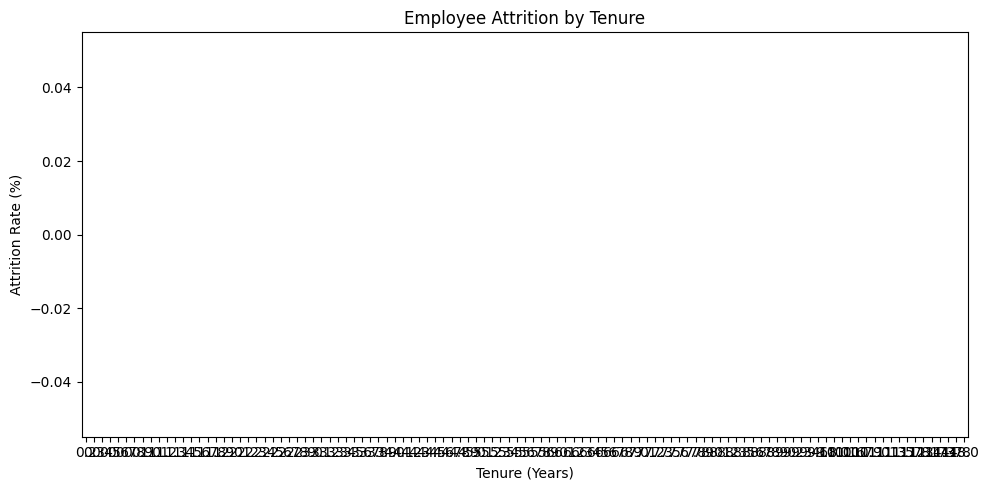

In [33]:

import matplotlib.pyplot as plt

tenure_attrition["attrition_rate_percent"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Employee Attrition by Tenure")
plt.xlabel("Tenure (Years)")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [34]:

highest_tenure_attrition = tenure_attrition[
    "attrition_rate_percent"
].idxmax()

highest_rate = tenure_attrition.loc[
    highest_tenure_attrition,
    "attrition_rate_percent"
]

print("Tenure with highest attrition:", highest_tenure_attrition, "years")
print("Attrition rate:", highest_rate, "%")


Tenure with highest attrition: 0.2 years
Attrition rate: 0.0 %


In [35]:
print(attendance.columns.tolist())

['employee_id', 'absence_days', 'overtime_hours_monthly', 'leave_days_yearly']


In [36]:

print("Attendance columns:")
print(attendance.columns.tolist())


Attendance columns:
['employee_id', 'absence_days', 'overtime_hours_monthly', 'leave_days_yearly']


In [37]:

for col in attendance.columns:
    if "overtime" in col.lower():
        print("Overtime column found:", col)


Overtime column found: overtime_hours_monthly


In [39]:

print("Attendance columns:")
print(attendance.columns.tolist())

print("\nOvertime-related columns:")
print([
    col for col in attendance.columns
    if "overtime" in col.lower()
])


Attendance columns:
['employee_id', 'absence_days', 'overtime_hours_monthly', 'leave_days_yearly']

Overtime-related columns:
['overtime_hours_monthly']


In [40]:

# Find the overtime column
overtime_cols = [
    col for col in master.columns
    if "overtime" in col.lower()
]

if not overtime_cols:
    print("Overtime column not found in master.")
    print("Please check the column names above.")
else:
    overtime_col = overtime_cols[0]
    print("Using column:", overtime_col)

    master[overtime_col] = pd.to_numeric(
        master[overtime_col], errors="coerce"
    )

    master["overtime_group"] = master[overtime_col].apply(
        lambda x: (
            "High Overtime" if x > 40
            else "Normal Overtime" if pd.notna(x)
            else "Unknown"
        )
    )

    overtime_attrition = master.groupby("overtime_group").agg(
        total_employees=("employee_id", "nunique"),
        employees_left=("left_flag", "sum")
    )

    overtime_attrition["attrition_rate_percent"] = (
        overtime_attrition["employees_left"]
        / overtime_attrition["total_employees"] * 100
    ).round(2)

    display(overtime_attrition)


Using column: overtime_hours_monthly


,total_employees,employees_left,attrition_rate_percent
overtime_group,,,
High Overtime,4,0,0.0
Normal Overtime,496,0,0.0


In [41]:

print("Engagement columns:")
print(engagement.columns.tolist())


Engagement columns:
['employee_id', 'survey_score', 'participation_percent']


In [42]:

score_cols = [
    col for col in master.columns
    if "survey" in col.lower() or "engagement" in col.lower()
]

print("Possible engagement columns:", score_cols)


Possible engagement columns: ['survey_score']


In [43]:

if not score_cols:
    print("No engagement score column found. Check the column names.")
else:
    score_col = score_cols[0]

    print("Using column:", score_col)

    master[score_col] = pd.to_numeric(
        master[score_col], errors="coerce"
    )

    engagement_summary = master.groupby("left_flag")[score_col].agg(
        ["count", "mean", "median"]
    )

    engagement_summary.index = engagement_summary.index.map({
        False: "Stayed",
        True: "Left"
    })

    display(engagement_summary)


Using column: survey_score


,count,mean,median
left_flag,,,
Stayed,472,3.443008,3.5


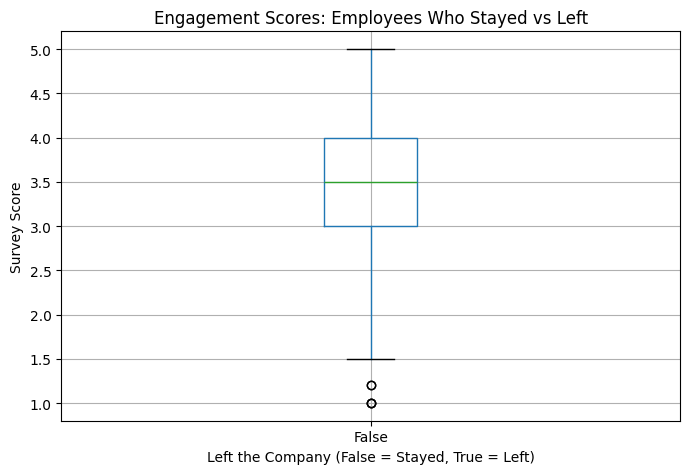

In [44]:

master.boxplot(
    column=score_col,
    by="left_flag",
    figsize=(7, 5)
)

plt.title("Engagement Scores: Employees Who Stayed vs Left")
plt.suptitle("")
plt.xlabel("Left the Company (False = Stayed, True = Left)")
plt.ylabel("Survey Score")
plt.tight_layout()
plt.show()


In [45]:

print("Movement columns:")
print(movement.columns.tolist())


Movement columns:
['employee_id', 'promotions_count', 'transfers_count', 'exit_status']


In [46]:

promotion_cols = [
    col for col in master.columns
    if "promotion" in col.lower()
]

print("Promotion columns found:", promotion_cols)


Promotion columns found: ['promotions_count']


In [47]:

if not promotion_cols:
    print("No promotion column found. Check the column names.")
else:
    promotion_col = promotion_cols[0]
    print("Using column:", promotion_col)

    master[promotion_col] = pd.to_numeric(
        master[promotion_col], errors="coerce"
    )

    master["promotion_group"] = master[promotion_col].apply(
        lambda x: (
            "No Promotion" if x == 0
            else "One or More Promotions" if pd.notna(x)
            else "Unknown"
        )
    )

    promotion_attrition = master.groupby("promotion_group").agg(
        total_employees=("employee_id", "nunique"),
        employees_left=("left_flag", "sum")
    )

    promotion_attrition["attrition_rate_percent"] = (
        promotion_attrition["employees_left"]
        / promotion_attrition["total_employees"] * 100
    ).round(2)

    display(promotion_attrition)


Using column: promotions_count


,total_employees,employees_left,attrition_rate_percent
promotion_group,,,
No Promotion,251,0,0.0
One or More Promotions,227,0,0.0
Unknown,22,0,0.0


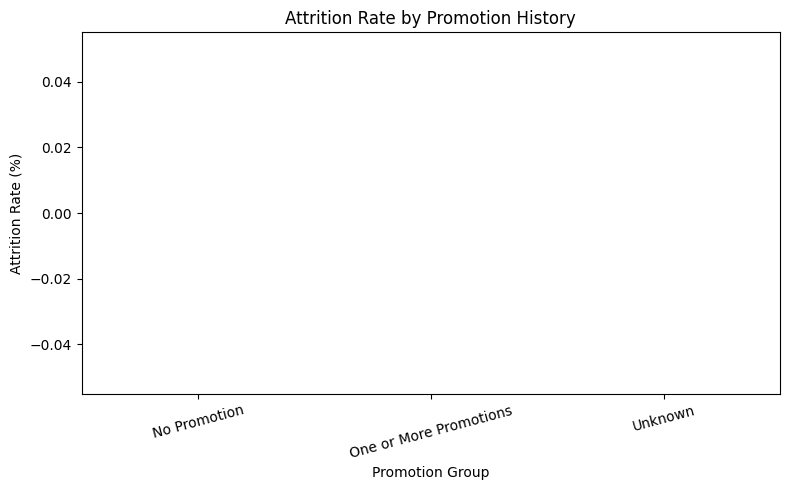

In [48]:

promotion_attrition["attrition_rate_percent"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Attrition Rate by Promotion History")
plt.xlabel("Promotion Group")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [49]:

role_attrition = master.groupby("role").agg(
    total_employees=("employee_id", "nunique"),
    employees_left=("left_flag", "sum")
)

role_attrition["attrition_rate_percent"] = (
    role_attrition["employees_left"]
    / role_attrition["total_employees"] * 100
).round(2)

display(
    role_attrition.sort_values(
        "attrition_rate_percent",
        ascending=False
    )
)


,total_employees,employees_left,attrition_rate_percent
role,,,
account manager,31,0,0.0
accountant,10,0,0.0
data analyst,35,0,0.0
engineering manager,30,0,0.0
finance manager,28,0,0.0
financial analyst,17,0,0.0
hr executive,17,0,0.0
hr manager,16,0,0.0
operations associate,44,0,0.0


In [50]:

master.to_csv("employee_attrition_master.csv", index=False)

from google.colab import files
files.download("employee_attrition_master.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>